<a href="https://colab.research.google.com/github/kamzy74/Disaster-Imagery-Classifier/blob/main/Data_C200_Grad_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Making `project_folder_path` Adaptable for Collaborators

When collaborating on Google Colab projects that involve files in Google Drive, it's common for file paths to differ slightly between users, especially if they organize their 'My Drive' differently or if files are shared via 'Shared with me'.

To make the `project_folder_path` more adaptable, your collaborators should:

1.  **Mount their own Google Drive:** This is always the first step: `drive.mount('/content/drive')`.
2.  **Locate the shared folder/file:** They need to find where the `DATA C200/Project` folder (or the `satellite-image-data.zip` file) is located within their mounted Google Drive (`/content/drive/My Drive/`).
    *   If you shared a folder with them, they might need to add it to their 'My Drive' first (right-click -> 'Add to My Drive').
    *   They can then browse their Drive using the file browser in Colab (left sidebar icon with a folder) or use `os.listdir('/content/drive/My Drive/')` to check directories.
3.  **Update the `project_folder_path` variable:** They should update the `project_folder_path` variable in the code cell below to precisely match the path to the directory containing `satellite-image-data.zip` within their mounted Google Drive.

For example, if they've moved your shared 'Project' folder directly into their 'My Drive' root, their path might look like:
`project_folder_path = '/content/drive/My Drive/Project'`

If it's deeply nested, it could be:
`project_folder_path = '/content/drive/My Drive/SomeFolder/AnotherFolder/Project'`

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount = True)

Mounted at /content/drive


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import zipfile
import os

In [ ]:

import os
# Use the corrected project_folder_path from earlier cells
# Assuming project_folder_path is defined in a previous cell
# If you run cells sequentially, project_folder_path should be available.
print(os.listdir(project_folder_path))

import glob
matches = glob.glob('/content/drive/My Drive/**/*.zip', recursive=True)
print(matches)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/My Drive/Project'

In [ ]:
# Collaborators: Please update this path to your specific location of the 'Project' folder within your mounted Google Drive.
# This folder should contain 'satellite-image-data.zip'.
project_folder_path = '/content/drive/My Drive/Project'

# The zip_file_path will then be constructed from this base path
zip_file_path = os.path.join(project_folder_path, 'satellite-image-data.zip')

print(f"Project folder path set to: {project_folder_path}")
print(f"Zip file path will be: {zip_file_path}")

extraction_path_satellite = '/content/satellite-image-data'

# Create the directory if it doesn't exist
os.makedirs(extraction_path_satellite, exist_ok=True)

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extraction_path_satellite)

print(f"'{zip_file_path}' unzipped to '{extraction_path_satellite}'")

Project folder path set to: /content/drive/My Drive/Project
Zip file path will be: /content/drive/My Drive/Project/satellite-image-data.zip


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/My Drive/Project/satellite-image-data.zip'

In [ ]:
# Load and save training and test datasets

base_data_path = os.path.join(extraction_path_satellite, 'satellite-image-data')
event_categories = ['midwest-flooding', 'socal-fire', 'hurricane-matthew']

train_datasets = {}
print("Loading training datasets...")
for category in event_categories:
    category_path = os.path.join(base_data_path, category)
    train_images_path = os.path.join(category_path, 'train_images.npz')
    train_labels_path = os.path.join(category_path, 'train_labels.npy')

    print(f"  Loading {category} data...")

    with np.load(train_images_path) as data:
        images = [data[key] for key in data.keys()]
        train_images = np.stack(images)

    train_labels = np.load(train_labels_path)

    train_datasets[category] = {
        'images': train_images,
        'labels': train_labels
    }
    print(f"    {category} images shape: {train_images.shape}, labels shape: {train_labels.shape}")

test_datasets = {}

print("\nLoading test datasets...")
test_files = [
    'test_images_hurricane-matthew.npz',
    'test_images_flooding-fire.npz'
]

for test_file in test_files:
    test_file_path = os.path.join(base_data_path, test_file)
    print(f"  Loading {test_file}...")
    with np.load(test_file_path) as data:
        images = [data[key] for key in data.keys()]
        test_images = np.stack(images)

    test_datasets[test_file.replace('.npz', '')] = test_images
    print(f"    {test_file.replace('.npz', '')} images shape: {test_images.shape}")

print("\nAll datasets loaded successfully!")
print("You can access them via 'train_datasets' and 'test_datasets' dictionaries.")

# Example of accessing data:
# print(train_datasets['hurricane-matthew']['images'].shape)
# print(train_datasets['hurricane-matthew']['labels'].shape)
# print(test_datasets['test_images_hurricane-matthew'].shape)

Loading training datasets...
  Loading midwest-flooding data...


FileNotFoundError: [Errno 2] No such file or directory: '/content/satellite-image-data/satellite-image-data/midwest-flooding/train_images.npz'

In [ ]:
training_data_save_path = os.path.join(project_folder_path, 'training_data')
test_data_save_path = os.path.join(project_folder_path, 'test_data')

# Create the new directories if they don't exist
os.makedirs(training_data_save_path, exist_ok=True)
os.makedirs(test_data_save_path, exist_ok=True)

print(f"Created training data save path: {training_data_save_path}")
print(f"Created test data save path: {test_data_save_path}")


Created training data save path: /content/drive/My Drive/Project/training_data
Created test data save path: /content/drive/My Drive/Project/test_data


In [ ]:
print("Saving training datasets to Google Drive...")
for category, data in train_datasets.items():
    images_filename = os.path.join(training_data_save_path, f'{category}_train_images.npz')
    np.savez_compressed(images_filename, images=data['images'])
    print(f"  Saved {category} training images to: {images_filename}")

    labels_filename = os.path.join(training_data_save_path, f'{category}_train_labels.npy')
    np.save(labels_filename, data['labels'])
    print(f"  Saved {category} training labels to: {labels_filename}")

print("Training datasets saved successfully.")


print("\n")
print("\n")
print("\n")
print("Saving test datasets to Google Drive...")
for test_file_name, images_array in test_datasets.items():
    # Save test images
    images_filename = os.path.join(test_data_save_path, f'{test_file_name}.npz')
    np.savez_compressed(images_filename, images=images_array)
    print(f"  Saved {test_file_name} test images to: {images_filename}")

print("Test datasets saved successfully.")


Saving training datasets to Google Drive...
  Saved midwest-flooding training images to: /content/drive/My Drive/Project/training_data/midwest-flooding_train_images.npz
  Saved midwest-flooding training labels to: /content/drive/My Drive/Project/training_data/midwest-flooding_train_labels.npy
  Saved socal-fire training images to: /content/drive/My Drive/Project/training_data/socal-fire_train_images.npz
  Saved socal-fire training labels to: /content/drive/My Drive/Project/training_data/socal-fire_train_labels.npy
  Saved hurricane-matthew training images to: /content/drive/My Drive/Project/training_data/hurricane-matthew_train_images.npz
  Saved hurricane-matthew training labels to: /content/drive/My Drive/Project/training_data/hurricane-matthew_train_labels.npy
Training datasets saved successfully.






Saving test datasets to Google Drive...
  Saved test_images_hurricane-matthew test images to: /content/drive/My Drive/Project/test_data/test_images_hurricane-matthew.npz
  Saved test

In [ ]:
# ============================================================
# CELL: Reload Images from Google Drive
# ============================================================
# GOAL: Reload the raw image arrays from the saved .npz files
# in Google Drive. We need these to generate our figures
# before we delete them from memory again.
#
# Earlier in the project we saved the processed datasets to:
# /content/drive/My Drive/Project/training_data/
# We can reload directly from there instead of re-unzipping
# the original file, which is faster.
# ============================================================

training_data_save_path = '/content/drive/My Drive/Project/training_data'

event_categories = ['midwest-flooding', 'socal-fire', 'hurricane-matthew']

train_datasets = {}

for cat in event_categories:

    # Load the images from the saved .npz file
    images_path = f"{training_data_save_path}/{cat}_train_images.npz"
    labels_path = f"{training_data_save_path}/{cat}_train_labels.npy"

    with np.load(images_path) as data:
        images = data['images']

    labels = np.load(labels_path)

    train_datasets[cat] = {
        'images': images,
        'labels': labels
    }

    print(f"Reloaded {cat}: images {images.shape}, labels {labels.shape}")

print("\n✅ All images reloaded successfully!")

NameError: name 'np' is not defined

In [ ]:
print(f"Contents of '{training_data_save_path}':")
print(os.listdir(training_data_save_path))

print(f"\nContents of '{test_data_save_path}':")
print(os.listdir(test_data_save_path))


Contents of '/content/drive/My Drive/Project/training_data':
['midwest-flooding_train_images.npz', 'socal-fire_train_images.npz', 'hurricane-matthew_train_images.npz', 'midwest-flooding_train_labels.npy', 'socal-fire_train_labels.npy', 'hurricane-matthew_train_labels.npy']

Contents of '/content/drive/My Drive/Project/test_data':
['test_images_hurricane-matthew.npz', 'test_images_flooding-fire.npz']


Section 1 — **Data Sampling and Collection**

In [ ]:
# ============================================================
# CELL: EDA Imports
# ============================================================

# seaborn and matplotlib are our visualization libraries
# seaborn builds on matplotlib and makes plots look cleaner with less code
import seaborn as sns
import matplotlib.pyplot as plt

# pandas is our main data manipulation library
# we use it to work with tables (DataFrames) and columns (Series)
import pandas as pd

# warnings is a built-in Python library
# we silence unimportant warning messages so our output stays readable
import warnings
warnings.filterwarnings('ignore')

print("✅ EDA imports ready.")

✅ EDA imports ready.


In [ ]:
# ============================================================
# CELL: Label Distribution
# ============================================================
# GOAL: Find out how many images belong to each damage label
# in each disaster category.
#
# This answers the EDA question:
# "What does the distribution of the data look like?"
# and checks for class imbalance — a faithfulness concern

# from our EDA framework (Lecture 5).
#
# For flooding and fire: labels are binary (0 = no damage, 1 = damage)
# For hurricane-matthew: labels are 0, 1, 2, 3 (damage levels)
# ============================================================

print("=" * 50)
print("LABEL DISTRIBUTION PER CATEGORY")
print("=" * 50)

for cat, d in train_datasets.items():

    # d['labels'] is a NumPy array of integers
    # We convert it to a pandas Series so we can use
    # .value_counts() — a method we learned in Pandas II
    label_series = pd.Series(d['labels'])

    print(f"\n{cat.upper()}")

    # .value_counts() counts how many times each unique label appears
    # .sort_index() sorts by label number (0, 1, 2, 3) instead of by frequency
    # This makes it easier to read in order
    print(label_series.value_counts().sort_index())

    # Print the total so we can confirm all 200 images loaded correctly
    print(f"Total images: {len(label_series)}")

LABEL DISTRIBUTION PER CATEGORY

MIDWEST-FLOODING
0    155
1      6
2      6
3     33
Name: count, dtype: int64
Total images: 200

SOCAL-FIRE
0     64
1      2
2      1
3    133
Name: count, dtype: int64
Total images: 200

HURRICANE-MATTHEW
0    31
1    70
2     6
3    93
Name: count, dtype: int64
Total images: 200


In [ ]:
# ============================================================
# CELL: Build Structured Feature DataFrame
# ============================================================
# GOAL: Convert our unstructured image arrays into a rectangular
# DataFrame (rows = images, columns = features).
#
# This is the core data cleaning step from Lecture 5:
# "A big part of data cleaning is reshaping data to be more rectangular."
#
# Instead of using a for loop, we use .map() with lambda functions
# to apply the same operation across every image in a Series.
# This is the pandas-style approach taught in Pandas II and III.
# ============================================================

# Step 1: Build a Series of images and a Series of labels for each category,
# then combine them all into one DataFrame using pd.concat.
# pd.concat stacks DataFrames on top of each other (row-wise).

category_dfs = []

for cat, d in train_datasets.items():

    # Create a temporary DataFrame for this category
    # Each row is one image — stored as a NumPy array in the 'image' column
    temp_df = pd.DataFrame({
        'category'    : cat,
        'damage_label': d['labels'].astype(int),
        'image'       : list(d['images'])  # store each image array as one cell
    })

    category_dfs.append(temp_df)

# Stack all three category DataFrames into one
# ignore_index=True resets the row numbers so they run 0 to 599
df = pd.concat(category_dfs, ignore_index=True)

# ── Step 2: Use .map() + lambda to extract features from each image ──────────
# .map() applies a function to every value in a Series, one at a time.
# lambda img: ... defines a short anonymous function that takes one image
# and returns one computed value. This is the pattern from Pandas II.

# Mean of the Red channel (channel index 0)
df['mean_r'] = df['image'].map(lambda img: img[:, :, 0].astype(float).mean())

# Mean of the Green channel (channel index 1)
df['mean_g'] = df['image'].map(lambda img: img[:, :, 1].astype(float).mean())

# Mean of the Blue channel (channel index 2)
df['mean_b'] = df['image'].map(lambda img: img[:, :, 2].astype(float).mean())


# Overall brightness = mean pixel value across ALL three channels combined
df['brightness'] = df['image'].map(lambda img: img.astype(float).mean())

# ── Step 3: Drop the raw image column ────────────────────────────────────────
# Now that we've extracted all the features we need, we no longer need
# to keep the raw image arrays in the DataFrame — they take up a lot of memory
# and aren't needed for EDA. We use .drop() from Pandas II.
df = df.drop('image', axis='columns')

# ── Step 4: Sanity check ──────────────────────────────────────────────────────
# We expect 600 rows (200 images x 3 categories) and 9 columns
print(f"DataFrame shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print()
df.head()

DataFrame shape: (600, 6)
Columns: ['category', 'damage_label', 'mean_r', 'mean_g', 'mean_b', 'brightness']



,category,damage_label,mean_r,mean_g,mean_b,brightness
0,midwest-flooding,0,107.508403,110.957174,88.973272,102.479616
1,midwest-flooding,0,70.532228,85.207410,51.954098,69.231245
2,midwest-flooding,0,42.695233,46.110619,31.279957,40.028603
3,midwest-flooding,0,57.182428,71.310020,42.995066,57.162505
4,midwest-flooding,1,77.788849,84.948372,57.696428,73.477883


In [ ]:
print(f"DataFrame shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

DataFrame shape: (600, 6)
Columns: ['category', 'damage_label', 'mean_r', 'mean_g', 'mean_b', 'brightness']


**Section 2 - Data Cleaning**


In [ ]:
# ============================================================
# CELL: Missing Value and Validity Check (no loops)
# ============================================================

numeric_cols = ['mean_r', 'mean_g', 'mean_b', 'brightness']

# Check for missing values in every column
print("Missing values per column:")
print(df.isna().sum())
print()

# Instead of a for loop, we use .map() on each column name
# to count how many values fall outside [0, 255]
#
# For each column name, the lambda:
#   1. Selects that column from df
#   2. Applies a boolean mask to find out-of-range values
#   3. Counts how many rows are flagged
out_of_range = pd.Series(numeric_cols).map(
    lambda col: df[(df[col] < 0) | (df[col] > 255)].shape[0]
)

# Pair the column names with their out-of-range counts
# for a clean readable output
out_of_range.index = numeric_cols
print("Out-of-range values per column:")
print(out_of_range)

Missing values per column:
category        0
damage_label    0
mean_r          0
mean_g          0
mean_b          0
brightness      0
dtype: int64

Out-of-range values per column:
mean_r        0
mean_g        0
mean_b        0
brightness    0
dtype: int64


**Section 3 - Exploratory Data Analysis**

In [ ]:
# ============================================================
# CELL: Summary Statistics with .describe()
# ============================================================
# GOAL: Get a quick statistical summary of all our numeric features.
#
# .describe() is from Pandas II — it returns count, mean, std,
# min, 25th percentile, median (50%), 75th percentile, and max
# for every numeric column in the DataFrame.
#
# This answers the milestone question:
#   "What does the distribution of the data look like?"
#
# We expect:
#   - count = 600 for every column (no missing values, confirmed above)
#   - All values between 0 and 255 (valid pixel range)
#   - Differences across categories will show up in the
#     visualizations we build next
# ============================================================

df.describe()

,damage_label,mean_r,mean_g,mean_b,brightness
count,600.000000,600.000000,600.000000,600.000000,600.000000
mean,1.468333,77.055337,86.038894,62.135417,75.076549
std,1.396034,20.308993,18.446503,15.426914,17.494497
min,0.000000,8.420226,10.447862,7.523170,9.393844
25%,0.000000,66.396272,77.700830,52.743255,66.045711
50%,1.000000,78.621749,87.684434,62.859732,76.601291
75%,3.000000,89.715431,98.086737,71.897989,86.348682
max,3.000000,139.766079,131.139871,108.486419,120.209046


In [ ]:
# ============================================================
# CELL: Summary Statistics Grouped by Category
# ============================================================
# GOAL: Compare the distribution of pixel features across
# the three disaster categories.
#
# Overall .describe() treats all 600 images the same.
# But we want to know: do flooding, fire, and hurricane
# images look different from each other?
#
# We use .groupby() from Pandas III to split the DataFrame
# into three groups (one per category) and compute the
# mean of each feature within each group.
#
# This directly addresses the EDA question:
# "Is there any correlation between the variables
#  we are interested in exploring?"
# ============================================================

# Group by disaster category and compute the mean of each
# numeric feature within each group.
# This tells us the "average look" of each disaster type.
numeric_cols = ['mean_r', 'mean_g', 'mean_b', 'brightness']

category_means = df.groupby('category')[numeric_cols].agg('mean').round(2)

print("Mean feature values per disaster category:")
print(category_means)
print()

# Now group by damage label to see how pixel values change
# as damage severity increases from 0 to 3
label_means = df.groupby('damage_label')[numeric_cols].agg('mean').round(2)

print("Mean feature values per damage label:")
print(label_means)

Mean feature values per disaster category:
                   mean_r  mean_g  mean_b  brightness
category                                             
hurricane-matthew   82.39   95.75   66.09       81.41
midwest-flooding    71.58   81.41   54.30       69.09
socal-fire          77.20   80.97   66.02       74.73

Mean feature values per damage label:
              mean_r  mean_g  mean_b  brightness
damage_label                                    
0              78.13   87.05   61.66       75.61
1              84.82   95.53   65.76       82.04
2              81.76   88.24   63.61       77.87
3              73.44   82.09   61.43       72.32


**Section 4 - Figures(tables, plots, etc.)**

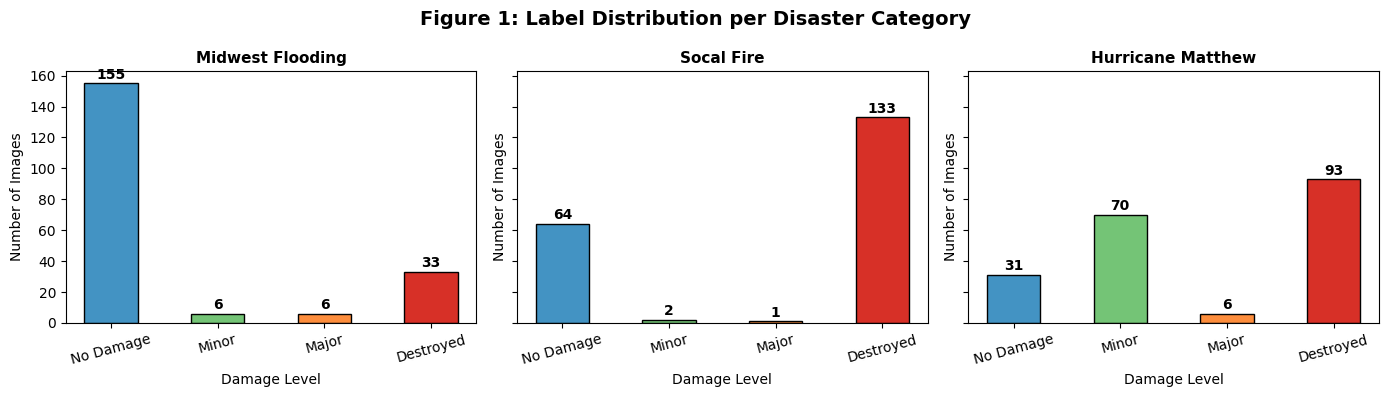

Saved: fig1_label_distribution.png


In [ ]:
# ============================================================
# CELL: Figure 1 — Label Distribution Bar Chart
# ============================================================
# GOAL: Visualize how many images belong to each damage label
# within each disaster category.
#
# This is our first figure. It directly answers the milestone
# question: "What does the distribution of the data look like?"
#
# We use matplotlib's plt.subplots() to create three side-by-side
# bar charts — one per category — so we can compare them easily.
#
# The class imbalance we found in .value_counts() earlier
# will be clearly visible here.
# ============================================================

# Create a figure with 3 side-by-side subplots (one per category)
# figsize controls the overall width and height of the figure
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

# A descriptive title for the whole figure
fig.suptitle("Figure 1: Label Distribution per Disaster Category",
             fontsize=14, fontweight='bold')

# Color each bar by damage level so they're easy to distinguish
# These colors go from blue (no damage) to red (destroyed)
label_colors = {0: '#4393c3', 1: '#74c476', 2: '#fd8d3c', 3: '#d73027'}
label_names  = {0: 'No Damage', 1: 'Minor', 2: 'Major', 3: 'Destroyed'}

for ax, cat in zip(axes, train_datasets.keys()):

    # Use .value_counts() to count images per label for this category
    # .sort_index() ensures bars appear in order 0, 1, 2, 3
    counts = pd.Series(train_datasets[cat]['labels']).value_counts().sort_index()

    # Build the bar chart
    # counts.index gives us the label numbers [0, 1, 2, 3]
    # counts.values gives us the corresponding counts
    bars = ax.bar(
        [label_names[i] for i in counts.index],
        counts.values,
        color=[label_colors[i] for i in counts.index],
        edgecolor='black',
        width=0.5
    )

    # Add the exact count on top of each bar for readability
    for bar, val in zip(bars, counts.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            str(val),
            ha='center', va='bottom',
            fontsize=10, fontweight='bold'
        )

    # Label each subplot with the category name
    ax.set_title(cat.replace('-', ' ').title(), fontsize=11, fontweight='bold')
    ax.set_xlabel("Damage Level")
    ax.set_ylabel("Number of Images")
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('fig1_label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig1_label_distribution.png")


In [ ]:
# ============================================================
# CELL: Check what's in our Project folder
# ============================================================
# GOAL: Find the correct path to our saved training data
# before trying to load it.
#
# We use os.listdir() to print the contents of the folder
# so we can confirm the exact file names and structure.
# ============================================================

import os

# Check the Project folder without (1)
project_path = '/content/drive/My Drive/UCB/MIMS/DATA C200/Project'

print("Contents of Project folder:")
print(os.listdir(project_path))

print()

# Check if training_data folder exists inside
training_path = f"{project_path}/training_data"
print("Contents of training_data folder:")
print(os.listdir(training_path))

Contents of Project folder:
['satellite-image-data.zip', 'training_data', 'test_data', 'Data C200 Grad Project', 'eda_features.csv']

Contents of training_data folder:
['midwest-flooding_train_images.npz', 'socal-fire_train_images.npz', 'hurricane-matthew_train_images.npz', 'midwest-flooding_train_labels.npy', 'socal-fire_train_labels.npy', 'hurricane-matthew_train_labels.npy']


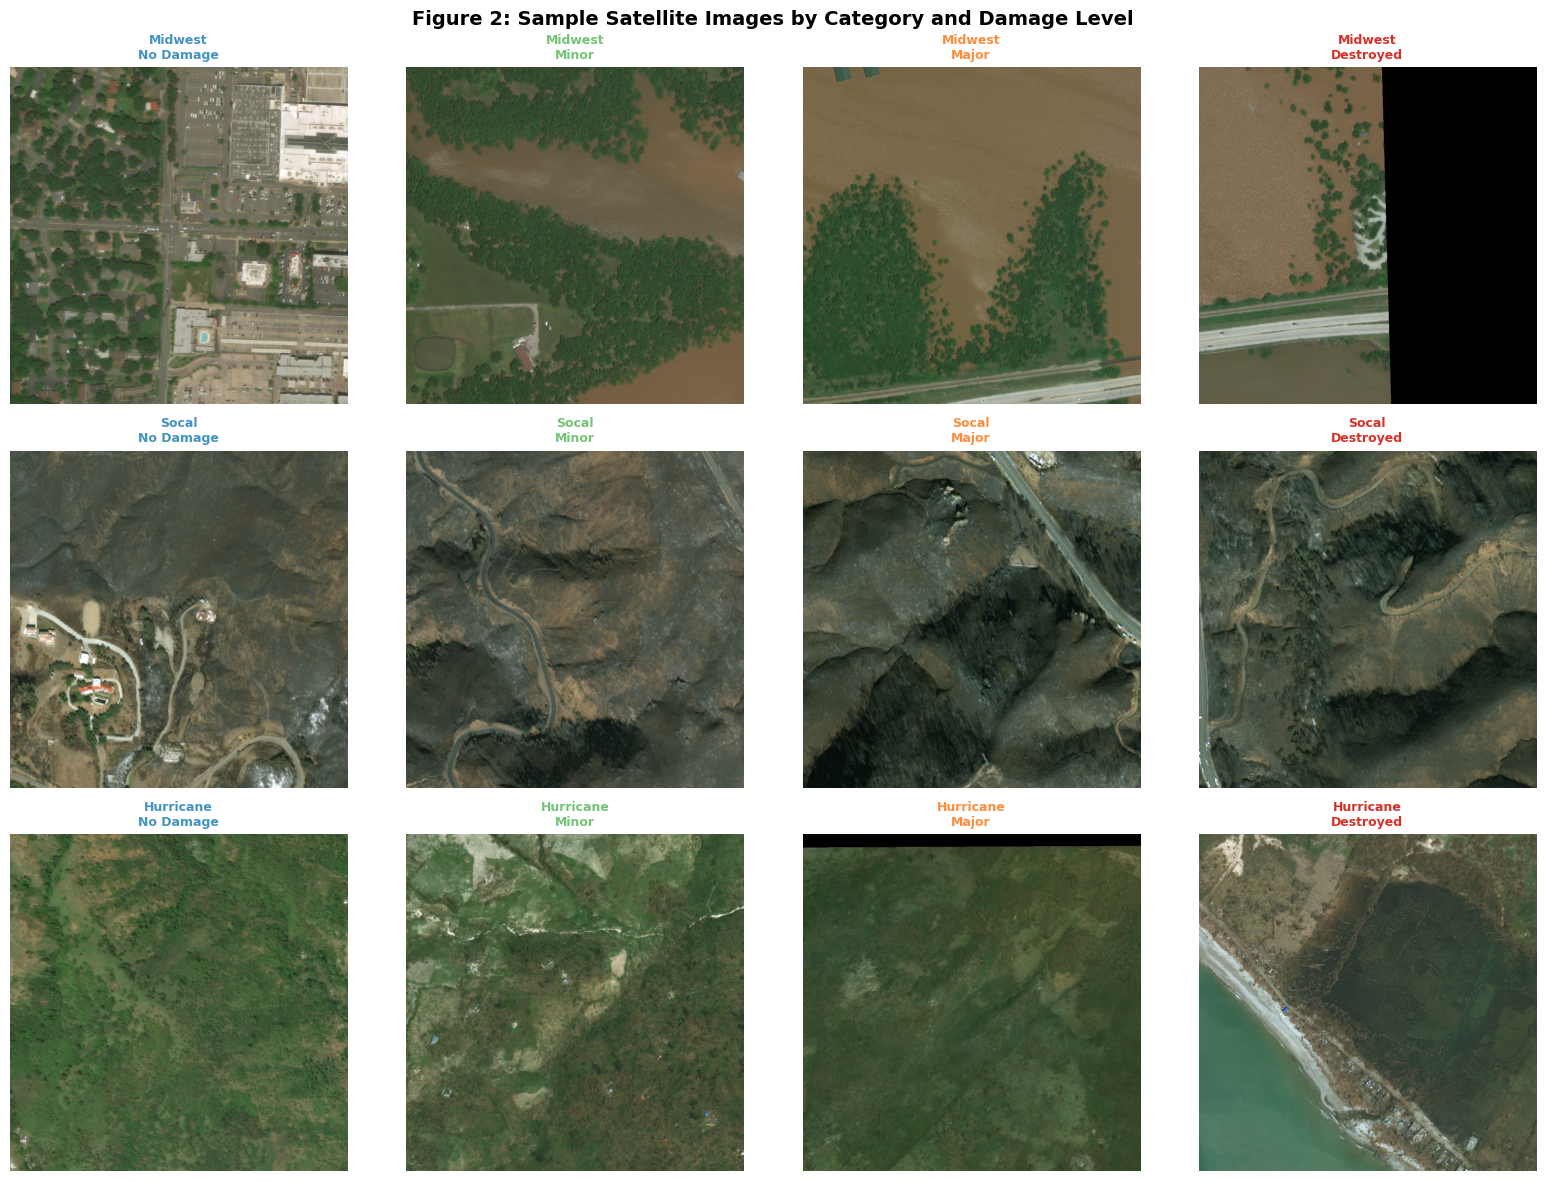

Saved: fig2_sample_images.png


In [ ]:
# ============================================================
# CELL: Figure 2 — Sample Satellite Images per Category
# ============================================================
# GOAL: Display representative satellite image tiles from
# each disaster category and damage level.
#
# This is a visual sanity check — it confirms our images
# loaded correctly and lets us see what the different
# damage levels actually look like from a satellite.
#
# We show one image per damage level per category.
# Since some categories are missing certain damage levels
# (e.g., SoCal Fire has almost no Minor or Major images),
# we only show levels that actually exist in that category.
# ============================================================

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle("Figure 2: Sample Satellite Images by Category and Damage Level",
             fontsize=14, fontweight='bold')

# Color-code the titles by damage level — same colors as Figure 1
label_colors = {0: '#4393c3', 1: '#74c476', 2: '#fd8d3c', 3: '#d73027'}
label_names  = {0: 'No Damage', 1: 'Minor', 2: 'Major', 3: 'Destroyed'}

for row, cat in enumerate(train_datasets.keys()):

    images = train_datasets[cat]['images']
    labels = train_datasets[cat]['labels']

    # Get one example image index for each damage level that exists
    # We use a list comprehension to find the first index where
    # the label matches each level — this is pandas-style thinking
    # applied to NumPy arrays
    label_series = pd.Series(labels)
    unique_levels = sorted(label_series.unique())

    # We have 4 columns in our grid — fill with available levels
    for col in range(4):

        ax = axes[row][col]

        if col < len(unique_levels):
            level = unique_levels[col]

            # .idxmax() returns the index of the first True value
            # in a boolean Series — this gives us the first image
            # with this damage level
            idx = (label_series == level).idxmax()

            # Display the image using imshow()
            ax.imshow(images[idx])

            # Title each image with its category and damage level
            # colored by damage severity
            ax.set_title(
                f"{cat.split('-')[0].title()}\n{label_names[level]}",
                fontsize=9,
                color=label_colors[level],
                fontweight='bold'
            )
        else:
            # If this category has fewer than 4 damage levels,
            # leave the extra subplot blank
            ax.set_visible(False)

        ax.axis('off')

plt.tight_layout()
plt.savefig('fig2_sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig2_sample_images.png")

**Section 3- Exploratory Data Analysis**

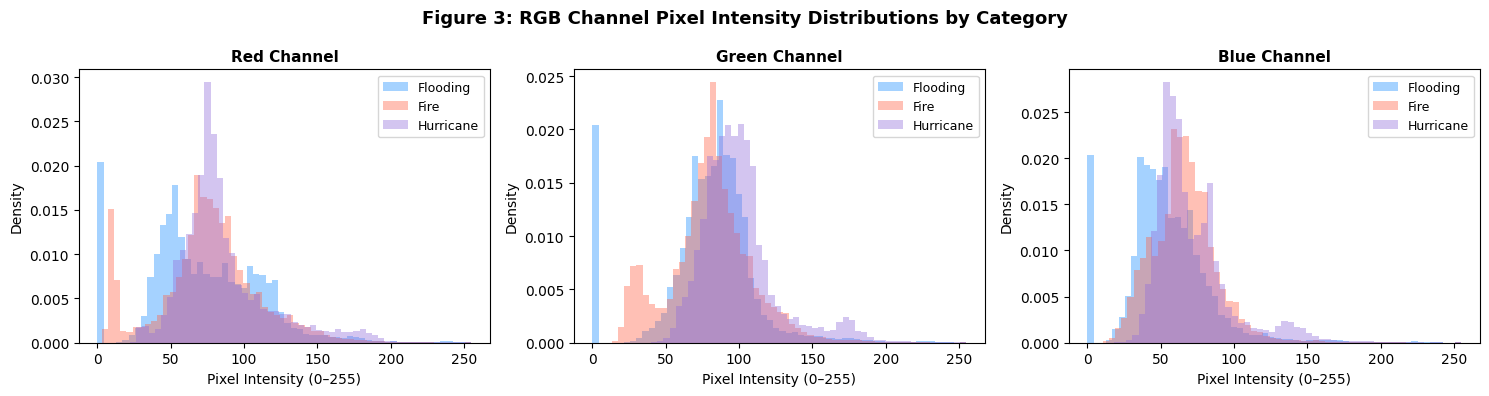

Saved: fig3_rgb_distributions.png


In [ ]:
# ============================================================
# CELL: Figure 3 — RGB Channel Distributions (Memory Efficient)
# ============================================================
# GOAL: Same as before — visualize pixel intensity distributions
# per color channel per category.
#
# To avoid crashing Colab due to RAM limits, we make two changes:
#   1. Only use 10 images per category instead of 50
#   2. Take every 4th pixel using slice notation [::4, ::4]
#      This gives us a representative sample of pixel values
#      without loading all 1024x1024 pixels into memory
#
# This is called "downsampling" — we're reducing resolution
# to make computation feasible while keeping the distribution
# shape roughly the same
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Figure 3: RGB Channel Pixel Intensity Distributions by Category",
             fontsize=13, fontweight='bold')

category_styles = {
    'midwest-flooding' : ('dodgerblue', 'Flooding'),
    'socal-fire'       : ('tomato',     'Fire'),
    'hurricane-matthew': ('mediumpurple','Hurricane')
}

channels = [('Red', 0), ('Green', 1), ('Blue', 2)]

for ax, (ch_name, ch_idx) in zip(axes, channels):

    for cat, (color, label) in category_styles.items():

        # Only use 10 images instead of 50
        # [::4, ::4] takes every 4th pixel in both dimensions
        # reducing each image from 1024x1024 to 256x256
        # This cuts memory use by 16x while preserving the
        # overall shape of the distribution
        pixels = train_datasets[cat]['images'][:10, ::4, ::4, ch_idx].flatten()

        sns.histplot(
            pixels,
            ax=ax,
            color=color,
            label=label,
            stat='density',
            bins=60,
            alpha=0.4,
            edgecolor='none'
        )

    ax.set_title(f"{ch_name} Channel", fontsize=11, fontweight='bold')
    ax.set_xlabel("Pixel Intensity (0–255)")
    ax.set_ylabel("Density")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig3_rgb_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig3_rgb_distributions.png")

In [ ]:
# ============================================================
# CELL: Free Up RAM After Figures Are Generated
# ============================================================
# GOAL: Delete the raw image arrays from memory now that
# we have saved all the figures that needed them.
#
# We keep the labels since they are tiny (just 200 integers
# per category). We also keep our feature DataFrame df
# since that's what all remaining analysis will use.
#
# Run this cell IMMEDIATELY after Figure 3 saves successfully.
# ============================================================

import gc

# Delete just the images, keep the labels
for cat in train_datasets.keys():
    del train_datasets[cat]['images']

# Force Python to release the freed memory right away
gc.collect()

print("✅ Raw images deleted from memory.")
print("✅ Labels still available via train_datasets[cat]['labels']")
print("✅ Feature DataFrame df still available.")
print(f"✅ df shape: {df.shape}")

✅ Raw images deleted from memory.
✅ Labels still available via train_datasets[cat]['labels']
✅ Feature DataFrame df still available.
✅ df shape: (600, 9)


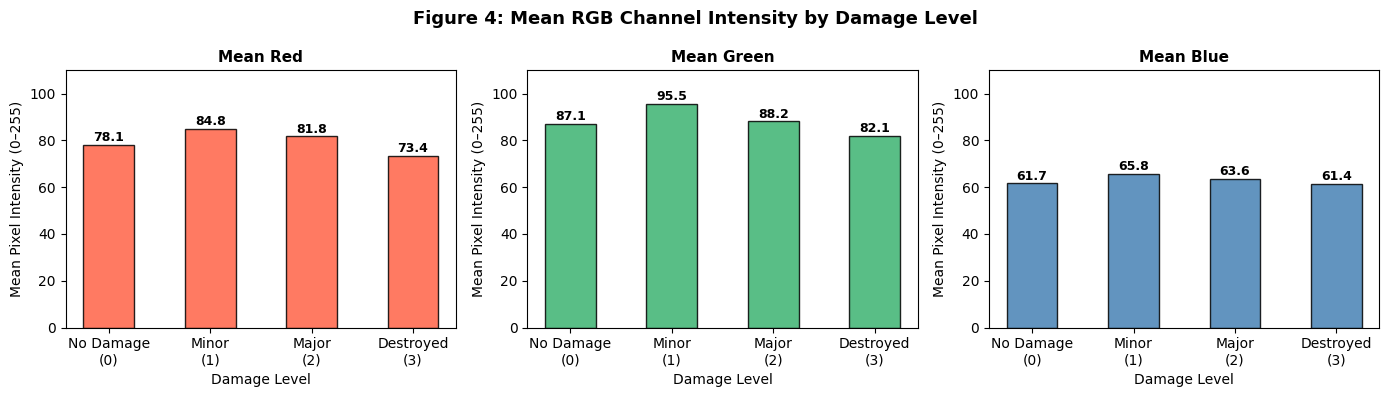

Saved: fig4_rgb_by_damage_level.png


In [ ]:
# ============================================================
# CELL: Figure 4 — Mean RGB by Damage Level
# ============================================================
# GOAL: Visualize how average pixel intensity changes across
# damage levels 0, 1, 2, 3 for each color channel.
#
# This answers the key EDA question from our proposal:
# "Do destroyed buildings (level 3) look measurably different
#  in color from mildly damaged ones (level 1)?"
#
# We use our feature DataFrame df and .groupby() from Pandas III
# to compute mean channel values per damage level, then plot
# grouped bar charts to compare them visually.
# ============================================================

# Use .groupby() to compute mean RGB values per damage level
# This is the same pattern from Pandas III —
# split by damage_label, apply mean, combine into a new DataFrame
damage_means = df.groupby('damage_label')[['mean_r', 'mean_g', 'mean_b']].agg('mean')

# Set up a 1x3 grid — one subplot per color channel
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("Figure 4: Mean RGB Channel Intensity by Damage Level",
             fontsize=13, fontweight='bold')

# Colors for each channel to make the chart intuitive
channel_info = [
    ('mean_r', 'Mean Red',   'tomato'),
    ('mean_g', 'Mean Green', 'mediumseagreen'),
    ('mean_b', 'Mean Blue',  'steelblue')
]

label_names = ['No Damage\n(0)', 'Minor\n(1)', 'Major\n(2)', 'Destroyed\n(3)']

for ax, (col, title, color) in zip(axes, channel_info):

    # damage_means.index gives us [0, 1, 2, 3]
    # damage_means[col] gives us the mean value for each level
    bars = ax.bar(
        label_names,
        damage_means[col],
        color=color,
        edgecolor='black',
        alpha=0.85,
        width=0.5
    )

    # Add the exact value on top of each bar
    for bar, val in zip(bars, damage_means[col]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f"{val:.1f}",
            ha='center', va='bottom',
            fontsize=9, fontweight='bold'
        )

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("Damage Level")
    ax.set_ylabel("Mean Pixel Intensity (0–255)")
    ax.set_ylim(0, 110)

plt.tight_layout()
plt.savefig('fig4_rgb_by_damage_level.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig4_rgb_by_damage_level.png")

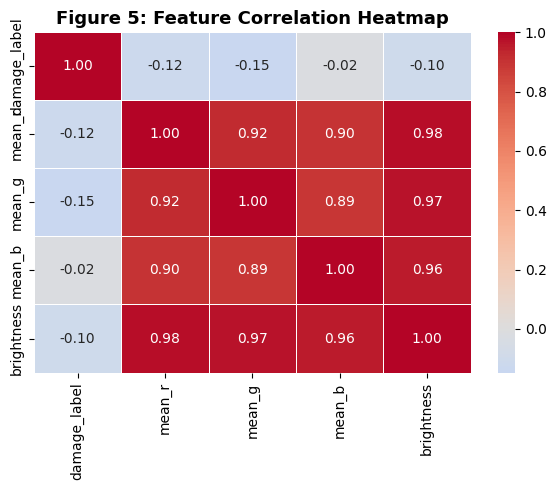

Saved: fig5_correlation_heatmap.png


In [ ]:
# ============================================================
# CELL: Figure 5 — Correlation Heatmap
# ============================================================
# GOAL: Visualize pairwise correlations between all numeric
# features in our DataFrame.
#
# This answers the milestone question:
# "Is there any correlation between the variables you are
#  interested in exploring?"
#
# A correlation value ranges from -1 to +1:
#   +1 = perfect positive relationship
#    0 = no relationship
#   -1 = perfect negative relationship
#
# We use df.corr() to compute the correlation matrix —
# this is a built-in pandas method that computes the
# Pearson correlation coefficient between every pair
# of numeric columns in the DataFrame.
#
# We then use seaborn's heatmap() to visualize it —
# warm colors (red) = strong positive correlation
# cool colors (blue) = strong negative correlation
# ============================================================

# Compute the correlation matrix using only numeric columns
# damage_label is included so we can see which features
# are most related to damage severity
numeric_cols = ['damage_label', 'mean_r', 'mean_g', 'mean_b',
                 'brightness']

corr_matrix = df[numeric_cols].corr()

# Set up the figure
fig, ax = plt.subplots(figsize=(6, 5))
ax.set_title("Figure 5: Feature Correlation Heatmap",
             fontsize=13, fontweight='bold')

# sns.heatmap() draws the correlation matrix as a colored grid
# annot=True prints the correlation value inside each cell
# fmt='.2f' rounds to 2 decimal places
# cmap='coolwarm' uses blue for negative, red for positive
# center=0 makes sure 0 correlation is shown as white
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    ax=ax,
    annot_kws={"size": 10}
)

plt.tight_layout()
plt.savefig('fig5_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig5_correlation_heatmap.png")

**NOT NEEDED section, Just saving the document**

In [ ]:
# ============================================================
# CELL: Save All Figures to Google Drive
# ============================================================
# GOAL: Copy all generated figures from Colab's temporary
# storage to Google Drive so they are permanently saved
# even if the session restarts or crashes.
#
# Colab's /content/ folder is temporary — everything in it
# disappears when the session ends. Google Drive is permanent.
# ============================================================

import shutil
import os

# Define where we want to save figures on Drive
figures_save_path = '/content/drive/My Drive/UCB/MIMS/DATA C200/Project (1)/figures'

# Create the figures folder if it doesn't already exist
os.makedirs(figures_save_path, exist_ok=True)

# List of all figures we've generated
figures = [
    'fig1_label_distribution.png',
    'fig2_sample_images.png',
    'fig3_rgb_distributions.png',
    'fig4_rgb_by_damage_level.png',
    'fig5_correlation_heatmap.png'
]

# Copy each figure from temporary Colab storage to Drive
for fig in figures:
    src = f'/content/{fig}'
    dst = f'{figures_save_path}/{fig}'
    shutil.copy(src, dst)
    print(f"✅ Saved {fig} to Drive")

print("\n✅ All figures safely saved to Google Drive!")

✅ Saved fig1_label_distribution.png to Drive
✅ Saved fig2_sample_images.png to Drive
✅ Saved fig3_rgb_distributions.png to Drive
✅ Saved fig4_rgb_by_damage_level.png to Drive
✅ Saved fig5_correlation_heatmap.png to Drive

✅ All figures safely saved to Google Drive!


In [ ]:
# ============================================================
# CELL: Save Feature DataFrame to Google Drive
# ============================================================
# GOAL: Save our feature DataFrame df as a CSV file to
# Google Drive so we don't have to rebuild it from scratch
# every time the session restarts.
#
# Once saved, we can reload it with pd.read_csv() instead
# of re-running the expensive .map() feature extraction cell.
# ============================================================

df_save_path = '/content/drive/My Drive/UCB/MIMS/DATA C200/Project/eda_features.csv'

# .to_csv() saves the DataFrame as a CSV file
# index=False prevents pandas from saving the row numbers
# as an extra column
df.to_csv(df_save_path, index=False)

print(f"✅ Feature DataFrame saved to Drive!")
print(f"   Path: {df_save_path}")
print(f"   Shape: {df.shape}")

✅ Feature DataFrame saved to Drive!
   Path: /content/drive/My Drive/UCB/MIMS/DATA C200/Project/eda_features.csv
   Shape: (600, 9)
